In [1]:
pip install matplotlib

  Using cached matplotlib-3.11.2-cp315-cp315-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp315-cp315-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp315-cp315-macosx_10_15_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp315-cp315-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp315-cp315-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp315-cp315-macosx_10_15_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp315-cp315-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-13.0.0-cp315-cp315-macosx_11_0_arm64.whl (4.9 MB)
Using cached pyparsing-3.3.3

In [2]:
words = open('names.txt', 'r').read().splitlines() 

In [3]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [5]:
min(len(w) for w in words)

2

In [6]:
max(len(w) for w in words)

15

In [19]:
# Building a bigram(pair of characters)
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>'] # add halucinations
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
        # print(ch1, ch2)

In [26]:
sorted(b.items(), key= lambda kv: -kv[1]) # sort the list of bigrams with their occurence, by count of occuence from most to least

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [27]:
import torch

In [53]:
N = torch.zeros((27 , 27), dtype=torch.int32)

In [59]:
chars = sorted(list(set(''.join(words)))) # all the characters we see
stoi = {s:i+1 for i,s in enumerate(chars)} # create a pair of link between the characters and an integer value
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [60]:
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1 # increment the biagram when obtained in the tensor

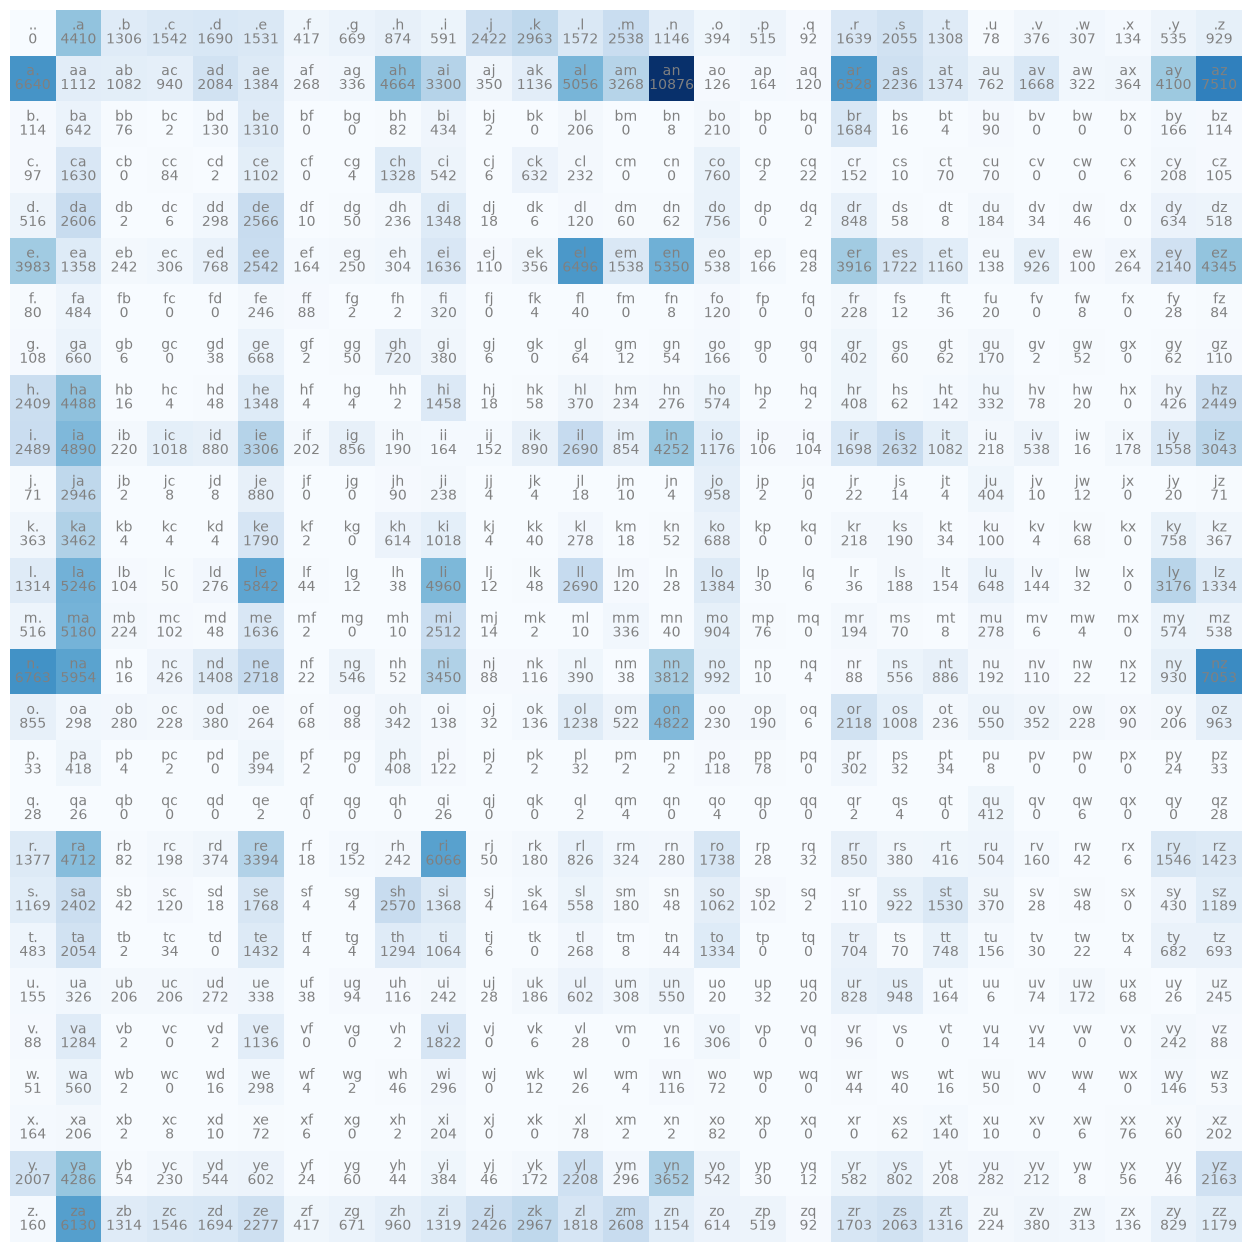

In [63]:
import matplotlib.pyplot as plt
%matplotlib inline
# plt.imshow(N)

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr=itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray') # populate the top part of the cell
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray') # the actual count from the recorded tensor
plt.axis('off');

In [67]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [69]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [72]:
torch.multinomial(p, num_samples=100, replacement=True, generator=g)

tensor([0, 2, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1,
        1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0, 0,
        2, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
        1, 0, 2, 0])